In [1]:
#1. 그래프 설정
from pathlib import Path
import sys
import time
import warnings
from datetime import datetime, timedelta, timezone
from concurrent.futures import ThreadPoolExecutor
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

fonts = {f.name for f in font_manager.fontManager.ttflist}
for name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if name in fonts:
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
print('실행 Python:', sys.executable)

실행 Python: /opt/anaconda3/bin/python3.13


In [2]:
########## 2. 실거래가와 아파트 좌표 파일 읽기 ##########
root = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data').exists()), None)
if root is None:
    raise FileNotFoundError('프로젝트 폴더 또는 src 폴더에서 실행하세요')
data = root / 'data'
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Workbook contains no default style')
    raw = pd.read_excel(data / '서울_아파트_매매_실거래가_2017-2026_통합.xlsx', sheet_name='아파트(매매) 실거래가', dtype=str,
                        usecols=['시군구', '전용면적(㎡)', '계약년월', '거래금액(만원)', '해제사유발생일', '주택유형'])
apt = pd.read_csv(data / '05_직주근접' / '아파트 좌표정보_서울시 공동주택 아파트 정보.csv', encoding='cp949')
print(f'실거래가: {len(raw):,}행 / 아파트 좌표: {len(apt):,}개 단지')

실거래가: 547,735행 / 아파트 좌표: 2,898개 단지


In [3]:
########## 3. 서울 아파트 매매만 남기고 ㎡당 가격 만들기 ##########
df = raw.apply(lambda s: s.str.strip())
num = lambda s: pd.to_numeric(s.str.replace(',', '', regex=False), errors='coerce')
df['가격_만원'] = num(df['거래금액(만원)'])
df['면적_m2'] = num(df['전용면적(㎡)'])
df['계약년'] = num(df['계약년월'].str[:4])
parts = df['시군구'].str.split()
df['자치구'] = parts.str[1]
df['법정동'] = parts.str[2]
cancelled = ~df['해제사유발생일'].fillna('').isin(['', '-', '0'])
keep = df['주택유형'].eq('아파트') & ~cancelled & df['가격_만원'].gt(0) & df['면적_m2'].gt(0) & df['계약년'].notna()
df = df[keep].copy()
df['m2당_만원'] = df['가격_만원'] / df['면적_m2']
df['log가격'] = np.log(df['m2당_만원'])
df['동키'] = df['자치구'] + ' ' + df['법정동']
print(f'분석 대상: {len(df):,}건 / {df["동키"].nunique()}개 동 / {int(df["계약년"].min())}~{int(df["계약년"].max())}년')

분석 대상: 530,129건 / 338개 동 / 2017~2026년


In [4]:
########## 4. 동별 대표 좌표 (세대수 가중 평균) ##########
a = apt.dropna(subset=['좌표X', '좌표Y']).copy()
a['동키'] = a['주소(시군구)'].str.strip() + ' ' + a['주소(읍면동)'].str.strip()
a['세대수'] = a['k-전체세대수'].fillna(1).clip(lower=1)
a['wx'] = a['좌표X'] * a['세대수']
a['wy'] = a['좌표Y'] * a['세대수']
g = a.groupby('동키')
origins = pd.DataFrame({'경도': g['wx'].sum() / g['세대수'].sum(), '위도': g['wy'].sum() / g['세대수'].sum(), '단지수': g.size()})
origins = origins[origins.index.isin(df['동키'].unique())]
covered = df['동키'].isin(origins.index).mean()
print(f'좌표가 있는 동: {len(origins)}개 / 거래 기준 비중 {covered:.1%}')
display(origins.head())

좌표가 있는 동: 276개 / 거래 기준 비중 99.5%


,경도,위도,단지수
동키,,,
강남구 개포동,127.0658,37.4851,23
강남구 논현동,127.0319,37.5149,14
강남구 대치동,127.0629,37.4974,25
강남구 도곡동,127.0466,37.4898,31
강남구 삼성동,127.0503,37.5158,25


In [5]:
########## 5. 업무지구와 출발 시각 ##########
hubs = pd.DataFrame({
    '업무지구': ['광화문', '강남', '여의도'],
    '위도': [37.5710, 37.4979, 37.5216],
    '경도': [126.9768, 127.0276, 126.9243],
}).set_index('업무지구')
kst = timezone(timedelta(hours=9))
day = datetime.now(kst).date() + timedelta(days=1)
while day.weekday() >= 5:
    day += timedelta(days=1)
depart = datetime(day.year, day.month, day.day, 8, 0, tzinfo=kst)
print('출발 시각:', depart.strftime('%Y-%m-%d (%a) %H:%M'))
display(hubs)

출발 시각: 2026-11-18 (Wed) 08:00


,위도,경도
업무지구,,
광화문,37.5710,126.9768
강남,37.4979,127.0276
여의도,37.5216,126.9243


In [6]:
########## 6. 구글 Routes API로 대중교통 소요시간 받기 ##########
cache = data / '05_직주근접' / '동별_업무지구_대중교통시간_구글.csv'
env = dict(line.split('=', 1) for line in (root / '.env').read_text().split() if '=' in line) if (root / '.env').exists() else {}
KEY = env.get('GOOGLE_MAPS_KEY')
MAX_CALLS = 1000
URL = 'https://routes.googleapis.com/directions/v2:computeRoutes'
HEADERS = {'Content-Type': 'application/json', 'X-Goog-Api-Key': KEY or '',
           'X-Goog-FieldMask': 'routes.duration,routes.distanceMeters,routes.legs.steps.travelMode'}

def route(dong, hub):
    o, h = origins.loc[dong], hubs.loc[hub]
    body = {'origin': {'location': {'latLng': {'latitude': o['위도'], 'longitude': o['경도']}}},
            'destination': {'location': {'latLng': {'latitude': h['위도'], 'longitude': h['경도']}}},
            'travelMode': 'TRANSIT', 'departureTime': depart.isoformat(), 'languageCode': 'ko'}
    for wait in [0, 2, 5, 10, 20]:
        time.sleep(wait)
        try:
            r = requests.post(URL, json=body, headers=HEADERS, timeout=60)
        except (requests.Timeout, requests.ConnectionError):
            continue
        if r.status_code == 200:
            routes = r.json().get('routes', [])
            if not routes:
                return {'동키': dong, '업무지구': hub, '분': np.nan, '거리_km': np.nan, '대중교통탑승수': np.nan}
            rt = routes[0]
            steps = [s['travelMode'] for leg in rt.get('legs', []) for s in leg.get('steps', [])]
            return {'동키': dong, '업무지구': hub, '분': int(rt['duration'].rstrip('s')) / 60,
                    '거리_km': rt.get('distanceMeters', 0) / 1000, '대중교통탑승수': steps.count('TRANSIT')}
        if r.status_code not in (429, 500, 503):
            raise RuntimeError(f'{r.status_code}: {r.text[:300]}')
    raise RuntimeError('재시도 실패: ' + dong + ' → ' + hub)

done = pd.read_csv(cache) if cache.exists() else pd.DataFrame(columns=['동키', '업무지구', '분', '거리_km', '대중교통탑승수'])
todo = [(d, h) for d in origins.index for h in hubs.index if not ((done['동키'] == d) & (done['업무지구'] == h)).any()]
print(f'저장된 결과: {len(done)}건 / 새로 받을 것: {len(todo)}건')
if todo:
    if not KEY:
        raise RuntimeError('.env에 GOOGLE_MAPS_KEY가 없습니다')
    if len(todo) > MAX_CALLS:
        raise RuntimeError(f'호출 수 {len(todo)}건이 상한 {MAX_CALLS}건을 넘습니다')
    with ThreadPoolExecutor(max_workers=4) as pool:
        for i in range(0, len(todo), 50):
            chunk = pd.DataFrame(list(pool.map(lambda x: route(*x), todo[i:i + 50]))).assign(출발시각=depart.isoformat())
            done = pd.concat([done, chunk], ignore_index=True)
            done.to_csv(cache, index=False, encoding='utf-8-sig')
            print(f'{min(i + 50, len(todo))}/{len(todo)}건 저장')
done[['분', '거리_km', '대중교통탑승수']] = done[['분', '거리_km', '대중교통탑승수']].apply(pd.to_numeric)
display(done.head())

저장된 결과: 828건 / 새로 받을 것: 0건


,동키,업무지구,분,거리_km,대중교통탑승수,출발시각
0,강남구 개포동,광화문,47.7167,17.0660,2,2026-11-18T08:00:00+09:00
1,강남구 개포동,강남,27.4333,6.6910,2,2026-11-18T08:00:00+09:00
2,강남구 개포동,여의도,43.7500,17.5820,2,2026-11-18T08:00:00+09:00
3,강남구 논현동,광화문,39.0500,9.4630,2,2026-11-18T08:00:00+09:00
4,강남구 논현동,강남,14.8167,3.0170,2,2026-11-18T08:00:00+09:00


In [7]:
########## 7. 동별 통근시간 표와 거래 데이터 합치기 ##########
commute = done.pivot(index='동키', columns='업무지구', values='분')[hubs.index].add_suffix('_분')
commute['최단통근_분'] = commute.min(axis=1)
commute['가까운업무지구'] = commute[[h + '_분' for h in hubs.index]].idxmin(axis=1).str[:-2]
print('경로 없음:', int(done['분'].isna().sum()), '건')
display(commute.describe().round(1))
df = df.merge(commute, left_on='동키', right_index=True, how='inner')
print(f'통근시간이 붙은 거래: {len(df):,}건 / {df["동키"].nunique()}개 동')

경로 없음: 0 건


업무지구,광화문_분,강남_분,여의도_분,최단통근_분
count,276.0000,276.0000,276.0000,276.0000
mean,35.3000,45.3000,35.7000,27.9000
std,14.2000,13.3000,14.9000,12.0000
min,9.1000,10.0000,8.5000,8.5000
25%,24.4000,37.0000,24.4000,18.4000
50%,34.7000,45.9000,34.1000,26.9000
75%,44.9000,53.4000,47.4000,36.1000
max,79.6000,76.9000,76.9000,65.8000


통근시간이 붙은 거래: 527,627건 / 276개 동


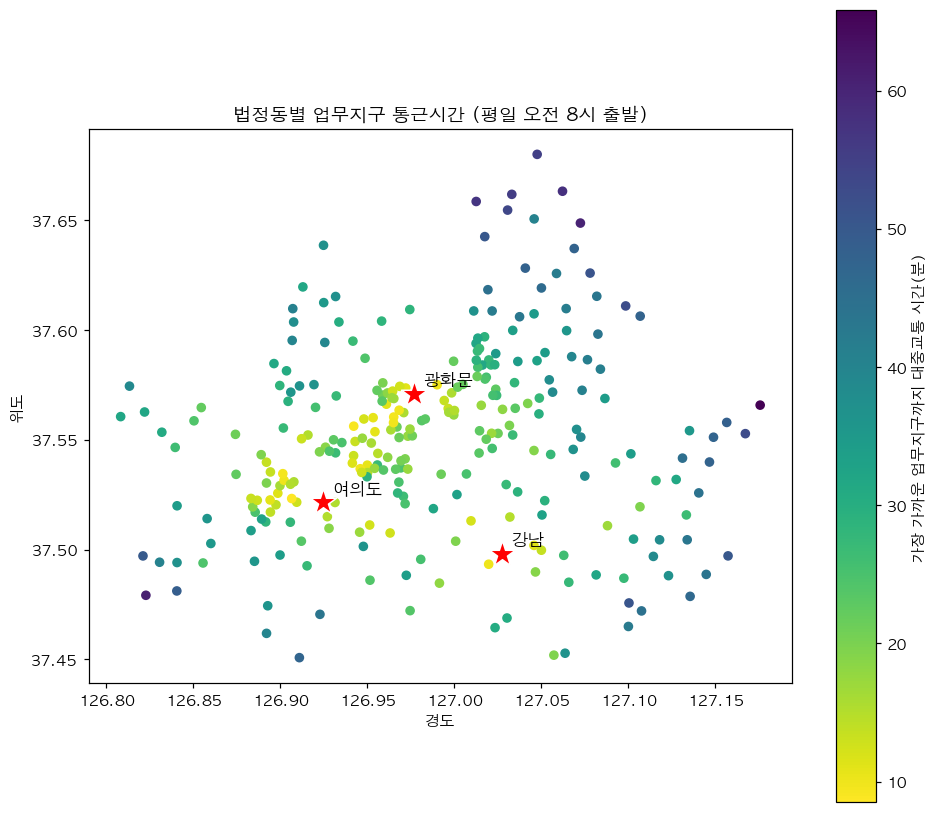

In [8]:
########## 8. 동별 최단 통근시간 지도 ##########
m = origins.join(commute, how='inner')
fig, ax = plt.subplots(figsize=(9, 7.5))
sc = ax.scatter(m['경도'], m['위도'], c=m['최단통근_분'], cmap='viridis_r', s=28)
ax.scatter(hubs['경도'], hubs['위도'], marker='*', s=320, color='red', edgecolor='white', zorder=3)
for name, r in hubs.iterrows():
    ax.annotate(name, (r['경도'], r['위도']), xytext=(6, 6), textcoords='offset points', fontsize=11, weight='bold')
fig.colorbar(sc, ax=ax, label='가장 가까운 업무지구까지 대중교통 시간(분)')
ax.set(title='법정동별 업무지구 통근시간 (평일 오전 8시 출발)', xlabel='경도', ylabel='위도')
ax.set_aspect(1 / np.cos(np.radians(37.55)))
plt.tight_layout()
plt.show()

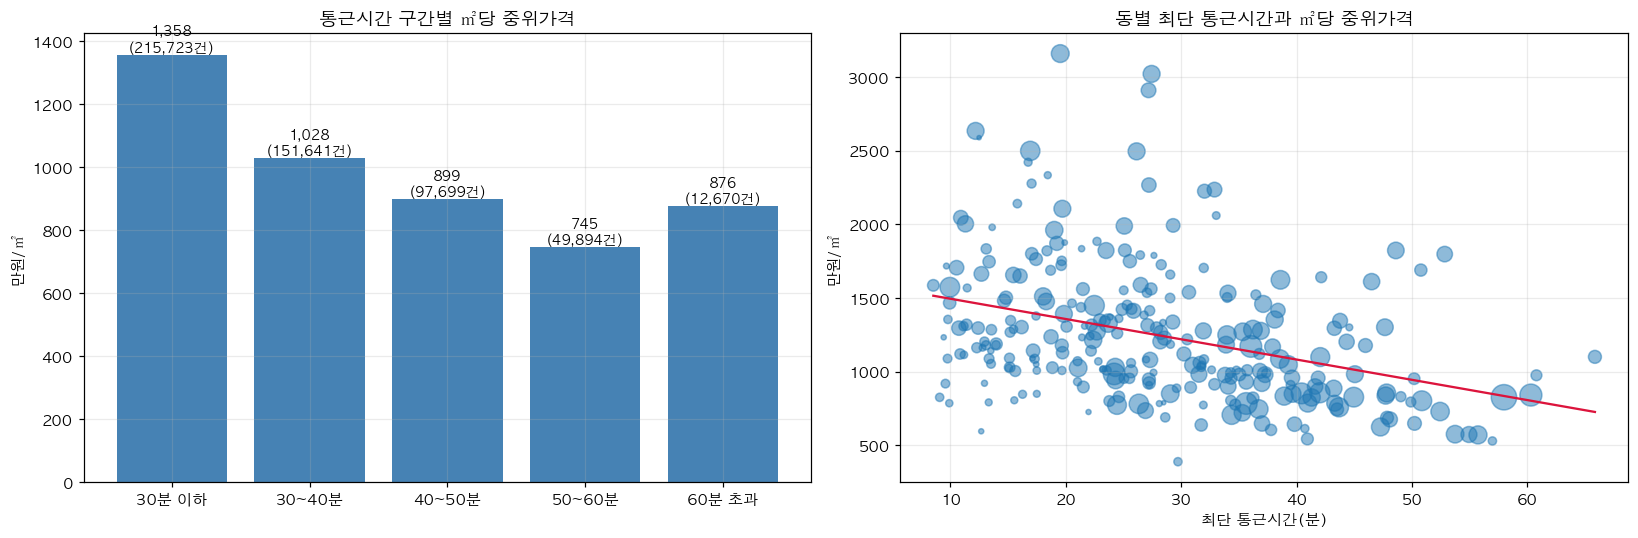

,거래수,m2당_중위_만원
통근구간,,
30분 이하,215723,"1,357.8869"
30~40분,151641,"1,028.0915"
40~50분,97699,898.8068
50~60분,49894,745.3995
60분 초과,12670,876.1584


In [9]:
########## 9. 통근시간 구간별 ㎡당 중위가격 ##########
bins = [0, 30, 40, 50, 60, np.inf]
labels = ['30분 이하', '30~40분', '40~50분', '50~60분', '60분 초과']
df['통근구간'] = pd.cut(df['최단통근_분'], bins=bins, labels=labels)
dong = df.groupby('동키').agg(m2당_중위=('m2당_만원', 'median'), 최단통근_분=('최단통근_분', 'first'), 거래수=('m2당_만원', 'size'))
table = df.groupby('통근구간', observed=True)['m2당_만원'].agg(['size', 'median'])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(table.index.astype(str), table['median'], color='steelblue')
for i, (n, v) in enumerate(zip(table['size'], table['median'])):
    axes[0].text(i, v, f'{v:,.0f}\n({n:,}건)', ha='center', va='bottom', fontsize=9)
axes[0].set(title='통근시간 구간별 ㎡당 중위가격', ylabel='만원/㎡')
axes[1].scatter(dong['최단통근_분'], dong['m2당_중위'], s=np.sqrt(dong['거래수']) * 2, alpha=0.5)
z = np.polyfit(dong['최단통근_분'], dong['m2당_중위'], 1)
xs = np.linspace(dong['최단통근_분'].min(), dong['최단통근_분'].max(), 50)
axes[1].plot(xs, np.polyval(z, xs), color='crimson')
axes[1].set(title='동별 최단 통근시간과 ㎡당 중위가격', xlabel='최단 통근시간(분)', ylabel='만원/㎡')
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
display(table.rename(columns={'size': '거래수', 'median': 'm2당_중위_만원'}))

In [10]:
########## 10. 학습·평가 데이터 나누기 ##########
df['동ID'] = pd.factorize(df['동키'])[0]
train, test = train_test_split(df, test_size=0.2, random_state=42)
print(f'학습: {len(train):,}건 / 평가: {len(test):,}건')

학습: 422,101건 / 평가: 105,526건


In [11]:
########## 11. 다중선형회귀 ##########
cl = lambda d: {'cov_type': 'cluster', 'cov_kwds': {'groups': d['동ID']}}
ols = smf.ols('log가격 ~ 최단통근_분 + C(자치구) + C(계약년)', data=train).fit(**cl(train))
ols3 = smf.ols('log가격 ~ 광화문_분 + 강남_분 + 여의도_분 + C(자치구) + C(계약년)', data=train).fit(**cl(train))
rows = []
for model, names in [(ols, ['최단통근_분']), (ols3, ['광화문_분', '강남_분', '여의도_분'])]:
    ci = model.conf_int().loc[names]
    for n in names:
        rows.append({'모형': '최단시간' if model is ols else '업무지구별', '변수': n, '계수': model.params[n],
                     '10분당_가격변화_%': (np.exp(10 * model.params[n]) - 1) * 100,
                     '95%CI_하한_%': (np.exp(10 * ci.loc[n, 0]) - 1) * 100,
                     '95%CI_상한_%': (np.exp(10 * ci.loc[n, 1]) - 1) * 100, 'p값': model.pvalues[n]})
ols_result = pd.DataFrame(rows).set_index(['모형', '변수'])
display(ols_result)
print(f'학습 R²: 최단시간 모형 {ols.rsquared:.3f} / 업무지구별 모형 {ols3.rsquared:.3f}')

계수  10분당_가격변화_%  95%CI_하한_%  95%CI_상한_%     p값
모형    변수                                                        
최단시간  최단통근_분 -0.0080      -7.7221    -11.4133     -3.8772 0.0001
업무지구별 광화문_분  -0.0038      -3.7349     -8.5141      1.2940 0.1429
      강남_분   -0.0038      -3.7223     -8.6329      1.4523 0.1556
      여의도_분  -0.0035      -3.3923     -8.0874      1.5427 0.1746

학습 R²: 최단시간 모형 0.603 / 업무지구별 모형 0.607


In [12]:
########## 12. Random Forest ##########
features = ['계약년', '자치구코드', '광화문_분', '강남_분', '여의도_분', '최단통근_분']
codes = {g: i for i, g in enumerate(sorted(df['자치구'].unique()))}
X_train = train.assign(자치구코드=train['자치구'].map(codes))[features].astype(float)
X_test = test.assign(자치구코드=test['자치구'].map(codes))[features].astype(float)
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf.fit(X_train, train['log가격'])
print('학습 완료: 나무', rf.n_estimators, '개')

학습 완료: 나무 200 개


In [13]:
########## 13. 두 모델 성능 비교 ##########
true = test['m2당_만원']
pred = {'다중선형회귀': np.exp(ols3.predict(test)), 'Random Forest': np.exp(rf.predict(X_test))}
score = pd.DataFrame({
    name: {'MAE_만원/㎡': mean_absolute_error(true, p),
           'RMSE_만원/㎡': mean_squared_error(true, p) ** 0.5,
           'R²': r2_score(true, p)}
    for name, p in pred.items()
}).T
display(score.round(3))

,MAE_만원/㎡,RMSE_만원/㎡,R²
다중선형회귀,321.7880,488.9350,0.5650
Random Forest,258.0180,390.0730,0.7230


,중요도,표준편차
강남_분,0.5934,0.0073
계약년,0.4320,0.0048
자치구코드,0.2613,0.0019
여의도_분,0.1483,0.0036
광화문_분,0.0895,0.0010
최단통근_분,0.0654,0.0013


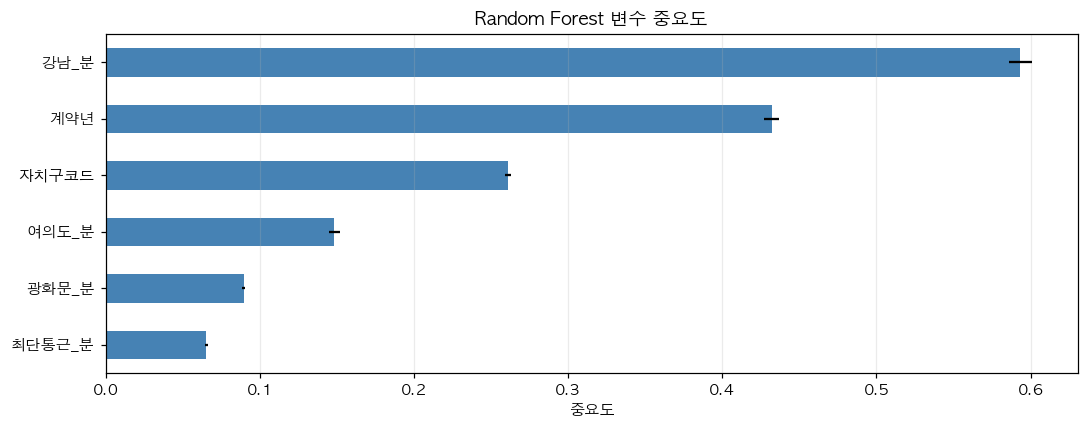

In [14]:
########## 14. 변수 중요도 (Permutation Importance) ##########
sample = X_test.sample(min(20000, len(X_test)), random_state=42)
pi = permutation_importance(rf, sample, test.loc[sample.index, 'log가격'], n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.DataFrame({'중요도': pi.importances_mean, '표준편차': pi.importances_std}, index=features).sort_values('중요도', ascending=False)
display(importance)
ax = importance['중요도'].sort_values().plot.barh(figsize=(10, 4), color='steelblue', xerr=importance['표준편차'])
ax.set(title='Random Forest 변수 중요도', xlabel='중요도', ylabel='')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

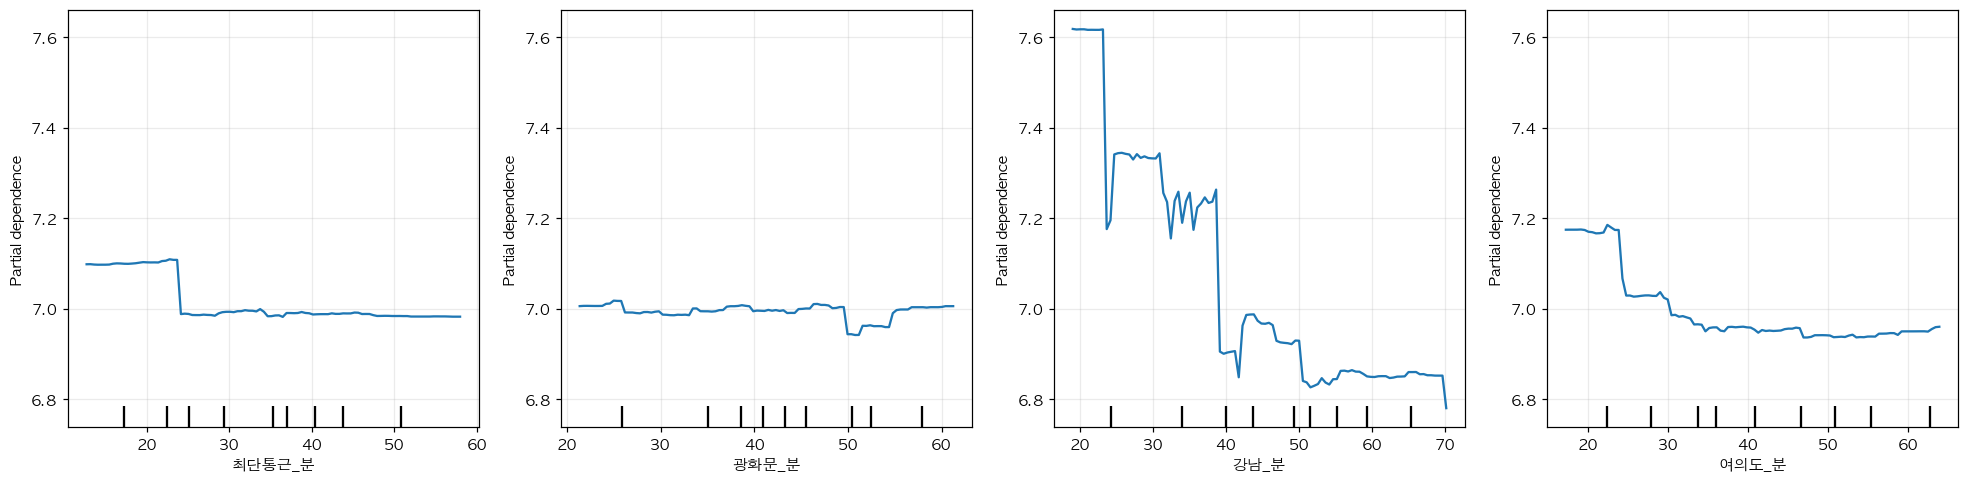

In [15]:
########## 15. 통근시간에 따른 예측가격 변화 ##########
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
PartialDependenceDisplay.from_estimator(rf, sample, ['최단통근_분', '광화문_분', '강남_분', '여의도_분'], ax=axes)
for ax in fig.axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [16]:
########## 16. 결과 요약 ##########
r = ols_result.loc[('최단시간', '최단통근_분')]
print(f"최단 통근시간 10분 증가 시 ㎡당 가격 {r['10분당_가격변화_%']:+.1f}% (95% CI {r['95%CI_하한_%']:+.1f}% ~ {r['95%CI_상한_%']:+.1f}%, p={r['p값']:.3f})")
for h in hubs.index:
    r = ols_result.loc[('업무지구별', h + '_분')]
    print(f"  {h}까지 10분 증가 시 {r['10분당_가격변화_%']:+.1f}% (p={r['p값']:.3f})")
print('RF 중요도 순위:', ' > '.join(importance.index))
best = score['R²'].idxmax()
print(f"평가 R²가 높은 모델: {best} ({score.loc[best, 'R²']:.3f})")
print('통근시간은 동 단위 값이고 자치구와 계약년을 통제한 같은 구 안 비교입니다.')

최단 통근시간 10분 증가 시 ㎡당 가격 -7.7% (95% CI -11.4% ~ -3.9%, p=0.000)
  광화문까지 10분 증가 시 -3.7% (p=0.143)
  강남까지 10분 증가 시 -3.7% (p=0.156)
  여의도까지 10분 증가 시 -3.4% (p=0.175)
RF 중요도 순위: 강남_분 > 계약년 > 자치구코드 > 여의도_분 > 광화문_분 > 최단통근_분
평가 R²가 높은 모델: Random Forest (0.723)
통근시간은 동 단위 값이고 자치구와 계약년을 통제한 같은 구 안 비교입니다.
